# T6: Retrieval design and evaluation

This notebook is the design document for the brief's extrinsic evaluation (T6): *"a
retrieval/agent that starts at a coarse level and drills down to find target nodes, versus a flat baseline, scored on
hit-rate or steps-to-target"*. It does four things:

1. It studies the format of the questions (`data/questions.csv`) and the ground-truth answers
   (`data/ground_truth.json`) (§2–§3).
2. It maps the ground truth onto the graph and measures what the export can answer at all (§4).
3. It describes the coarsening hierarchy as a search index (§5).
4. It describes the agent and its flat baseline (§6), defines the metrics (§7), runs both on all 18 questions
   (§8), and summarises the findings, the implementation and future work (§9).

**Inputs:**
- the run configuration (`configs/default.toml` or `$TKH_CONFIG`);
- the graph export;
- the run's hierarchies, `out/<cutoff>/hierarchy.json`, which are read, never rebuilt;
- the two data files.

**Implementation.** The agent is `tkh/retrieve.py` and the evaluator `eval/retrieval.py`; this notebook calls them.
`make retrieval` (part of `make all`) runs the same evaluation and writes `out/metrics.json["retrieval"]` and
`out/retrieval_answers.json`; the results are reported in `docs/report.md` §5. There are no LLM calls and
no network.

**Scope.** The task is kept to building the agent and evaluating it:
- **retrieval targets:** methods, claims and citations. Type A answers with methods, their claims and citations; type B
  with claims and citations. GT method names are matched to graph nodes by exact name or acronym only;
- **evaluation:** hit-rate, error rate, items inspected (the reader's effort) and candidates scored (computation),
  drill-down vs flat search (§7).

Everything left out is listed at the end as future work (§9).

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "tkh").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from collections import Counter
import inspect
import json
import re
import tempfile

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from eval.retrieval import METRICS, resolve_gold, retrieval_check
from tkh.config import load_config
from tkh.io import load
from tkh import retrieve
from tkh.retrieve import BEAM, KINDS, Agent, Facts, Index, choose_snapshot, leaf_texts, tree

print(f"python {sys.version.split()[0]}, pandas {pd.__version__}, matplotlib {matplotlib.__version__}")
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

cfg = load_config()  # honours $TKH_CONFIG
CUTOFFS, RUN, FIG = cfg.cutoffs, cfg.out_dir, cfg.figures_dir
FIG.mkdir(parents=True, exist_ok=True)
QUESTIONS, GT_PATH = ROOT / "data" / "questions.csv", ROOT / "data" / "ground_truth.json"
tkh = load(cfg)
H = {c: json.loads((RUN / str(c) / "hierarchy.json").read_text()) for c in CUTOFFS}
print(f"config: {os.path.relpath(cfg.source, ROOT)}\nrun: {os.path.relpath(RUN, ROOT)}\n{len(tkh.nodes)} nodes, {len(tkh.edges)} hyper-edges, "
      f"{len(tkh.articles)} articles; cutoffs {CUTOFFS}")

python 3.12.11, pandas 3.0.6, matplotlib 3.11.2
config: configs/default.toml
run: out
5798 nodes, 1429 hyper-edges, 52 articles; cutoffs (2020, 2022, 2024, 2026)


## 2. Questions: `data/questions.csv`

The file is `;`-separated with three columns: `question_id`, `question` and `type`. The type is metadata. A means
*specific search*: the answer is a list of methods (or datasets) plus their citations. B means *synthesis of
evidence*: the answer is a list of claims plus their citations.

The questions are written to a few templates. Most name an as-of date in parentheses ("by Feb 2026"). The cell below
parses, for each question:
- the template;
- the task phrase (after "for", before "when");
- the condition clause (after "when");
- the date cue.

In [2]:
qdf = pd.read_csv(QUESTIONS, sep=";", dtype=str)
print(qdf.shape, list(qdf.columns), dict(qdf["type"].value_counts()))

TEMPLATES = [("which methods ... best suited for X [when Y]", r"^which methods .*best suited for "),
             ("what are the leading X", r"^what are the leading"),
             ("what datasets and benchmarks", r"^what datasets"),
             ("what are the most important open challenges", r"^what are the most important"),
             ("how does X improve Y", r"^how does"),
             ("give evidence that X", r"^give evidence"),
             ("what mechanisms ... and what evidence", r"^what mechanisms")]



def parse(q):
    low = q.lower()
    tpl = next((name for name, rx in TEMPLATES if re.search(rx, low)), "other")
    task = re.search(r"\bfor (.+?)(?:\bwhen\b|\?|$)", re.sub(r"\([^)]*\)", "", q), re.I)
    cond = re.search(r"\bwhen (.+?)(?:\?|$)", q, re.I)
    date = re.search(r"\(([^)]*\d{4}[^)]*)\)", q)
    return tpl, task.group(1).strip() if task else "", cond.group(1).strip() if cond else "", date.group(1) if date else ""


rows = []
for _, r in qdf.iterrows():
    tpl, task, cond, date = parse(r["question"])
    snap, year, src = choose_snapshot(r["question"], CUTOFFS)   # tkh.retrieve
    rows.append({"id": r["question_id"], "type": r["type"], "words": len(r["question"].split()), "template": tpl,
                 "date cue": date, "as-of year": year, "snapshot": snap, "snapshot source": src,
                 "task phrase": task[:60], "condition": cond[:60]})
Q = pd.DataFrame(rows).set_index("id")
print("edge cases:", {t: choose_snapshot(t, CUTOFFS) for t in ("Which methods (by March 2023) work?", "Which methods by 2019?", "How does X work?")})
Q

(18, 3) ['question_id', 'question', 'type'] {'A': np.int64(14), 'B': np.int64(4)}
edge cases: {'Which methods (by March 2023) work?': (2022, 2023, 'stated'), 'Which methods by 2019?': (None, 2019, 'before_first_cutoff'), 'How does X work?': (2026, None, 'default_latest')}


,type,words,template,date cue,as-of year,snapshot,snapshot source,task phrase,condition
id,,,,,,,,,
Q1,A,27,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,predicting interatomic potentials,balancing accuracy close to DFT with computational efficienc
Q2,A,25,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,accelerating electronic structure calculations,self-consistent field iterations become prohibitively expens
Q3,A,25,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,learning DFT Hamiltonians,dealing with twisted van der Waals heterostructures containi
Q4,A,21,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,phonon property prediction,universal MLIPs show inaccuracies despite good energy/force
Q5,A,22,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,coarse-graining molecular dynamics,crystalline symmetries and long-range elastic interactions m
Q6,A,25,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,predicting ionic conductivity,full ab initio MD is too expensive but accuracy must be main
Q7,A,20,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,predicting phase transitions,"screening ~50,000 inorganic compounds at high throughput"
Q8,A,22,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,predicting fracture patterns,generalizing from atomistic MD data to unseen bicrystalline
Q9,A,21,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,ensuring physical consistency,transferring information between scales without violating th


**Observations:**
- **Templates.** Q1–Q11 share one template, "which methods … best suited for <task> when <condition>"; Q11 has no
  condition. Q12–Q14 ask for the leading methods or datasets. Q15–Q18 are synthesis questions with four different
  templates.
- **Dates.** Every question but Q16 states "by Feb 2026". Q16 has no date cue, so it gets the latest snapshot, and
  this is recorded.
- **Snapshot granularity.** Snapshots are yearly (cutoffs 2020/2022/2024/2026). "Feb 2026" maps to the ≤2026
  snapshot, which cannot exclude papers published later in 2026; §4 checks how many there are.

**Design choice D1, snapshot rule** (`tkh.retrieve.choose_snapshot`): the latest cutoff not after the stated year; no date → the latest cutoff; a date
before the first cutoff → no snapshot, so the agent abstains.
- Rationale: it never uses content after the question's date (P6), and it is deterministic.
- Rejected: always the latest snapshot, which would leak for earlier dates. Interpolating between snapshots isn't
  possible, because snapshots are cumulative and cut by year.
- Trade-off: within-year granularity is lost.

## 3. Ground truth: `data/ground_truth.json`

The file is a dict keyed by question id, and every entry has a `type`. The cells below inventory every field at every
nesting level, check the cross-references between fields, and assign each field a role in the evaluation.

In [3]:
gt = json.loads(GT_PATH.read_text())
A = {q: v for q, v in gt.items() if v["type"] == "A"}
B = {q: v for q, v in gt.items() if v["type"] == "B"}
assert set(gt) == set(qdf["question_id"]) and all(gt[q]["type"] == t for q, t in zip(qdf["question_id"], qdf["type"]))


def presence(entries):
    keys = sorted({k for v in entries for k in v})
    return pd.Series({k: sum(k in v for v in entries) for k in keys}, name=f"present in (of {len(entries)})")


print("type A, top level:"); display(presence(list(A.values())).to_frame())
print("type A, method_evidence items:"); display(presence([e for v in A.values() for m in v["method_evidence"].values() for e in m]).to_frame())
print("type A, fp_categories:"); display(presence([v["fp_categories"] for v in A.values() if "fp_categories" in v]).to_frame())
print("type B, top level:"); display(presence(list(B.values())).to_frame())
print("type B, required_claims items:"); display(presence([c for v in B.values() for c in v["required_claims"]]).to_frame())
print("type B, sources items:"); display(presence([s for v in B.values() for s in v["sources"].values()]).to_frame())

type A, top level:


,present in (of 14)
expected_methods,14
fp_categories,12
method_claims,14
method_evidence,14
required_citations,14
type,14


type A, method_evidence items:


,present in (of 188)
evidence,188
location,188
source,188


type A, fp_categories:


...

,present in (of 4)
as_of,4
contrast_sources,1
provenance_policy,1
required_citations,4
required_claims,4
sources,4
type,4


type B, required_claims items:


,present in (of 36)
caveat,23
contrast,1
coverage,36
distractor_note,7
evidence,36
flag,12
id,36
independence,6
locations,33
regime_scope,2


type B, sources items:


,present in (of 19)
date,19
doi,12
evidence_type,19
key,19
note,14
title,19
venue,19
verification,2
verified,5


In [4]:
def a_row(q, v):
    fp = v.get("fp_categories", {})
    return {"expected_methods": len(v["expected_methods"]), "method_claims": sum(map(len, v["method_claims"].values())),
            "method_evidence": sum(map(len, v["method_evidence"].values())), "required_citations": len(v["required_citations"]),
            "wrong_domain": len(fp.get("wrong_domain", [])), "outdated_as_main": len(fp.get("outdated_as_main", [])),
            "valid_but_unlisted": len(fp.get("valid_but_unlisted", [])), "has fp_categories": "fp_categories" in v}


def b_row(q, v):
    cl = v["required_claims"]
    return {"as_of": v["as_of"], "sources": len(v["sources"]), "required_claims": len(cl),
            **{f"coverage={c}": sum(x["coverage"] == c for x in cl) for c in ("full", "partial", "asserted_only")},
            "multi-source claims": sum(len(x["sources"]) > 1 for x in cl),
            "with independence": sum("independence" in x for x in cl), "with distractor_note": sum("distractor_note" in x for x in cl),
            "with contrast": sum("contrast" in x for x in cl), "required_citations": len(v["required_citations"]),
            "contrast_sources": len(v.get("contrast_sources", {}))}


display(pd.DataFrame({q: a_row(q, v) for q, v in A.items()}).T)
display(pd.DataFrame({q: b_row(q, v) for q, v in B.items()}).T)

,expected_methods,method_claims,method_evidence,required_citations,wrong_domain,outdated_as_main,valid_but_unlisted,has fp_categories
Q1,7,21,21,7,3,1,2,True
Q2,3,10,10,7,3,0,4,True
Q3,2,6,6,2,3,1,2,True
Q4,3,9,9,3,3,0,2,True
Q5,2,6,6,2,3,0,3,True
Q6,3,9,9,3,3,0,3,True
Q7,2,6,6,2,3,1,2,True
Q8,2,6,6,2,3,1,2,True
Q9,3,9,9,2,3,2,2,True
Q10,2,6,6,4,3,2,3,True


,as_of,sources,required_claims,coverage=full,coverage=partial,coverage=asserted_only,multi-source claims,with independence,with distractor_note,with contrast,required_citations,contrast_sources
Q15,2026-02,5,10,7,1,2,7,1,1,0,5,0
Q16,2026-02,4,9,8,1,0,3,1,3,0,4,0
Q17,2026-02,5,7,7,0,0,3,3,0,1,5,1
Q18,2026-02,5,10,9,1,0,5,1,3,0,5,0


In [5]:
# Cross-reference checks between fields (these define how the evaluator may join them)
checks = []
for q, v in A.items():
    em = set(v["expected_methods"])
    checks.append((q, "method_claims keys == expected_methods", set(v["method_claims"]) == em))
    checks.append((q, "method_evidence keys == expected_methods", set(v["method_evidence"]) == em))
    srcs = {e["source"] for m in v["method_evidence"].values() for e in m}
    checks.append((q, "evidence sources ⊆ required_citations", srcs <= set(v["required_citations"])))
    checks.append((q, "required_citations ⊆ evidence sources", set(v["required_citations"]) <= srcs))
    fp = {n for xs in v.get("fp_categories", {}).values() for n in xs}
    checks.append((q, "fp names disjoint from expected_methods", not (fp & em)))
for q, v in B.items():
    keys = set(v["sources"])
    checks.append((q, "required_citations ⊆ sources", set(v["required_citations"]) <= keys))
    checks.append((q, "claim sources ⊆ sources", all(set(c["sources"]) <= keys for c in v["required_claims"])))
    checks.append((q, "claim locations keyed by its sources",
                   all(set(c.get("locations", {})) <= set(c["sources"]) for c in v["required_claims"])))
    contrast = {s for c in v["required_claims"] for s in c.get("contrast", [])}
    checks.append((q, "claim contrast ⊆ contrast_sources", contrast <= set(v.get("contrast_sources", {}))))
ck = pd.DataFrame(checks, columns=["q", "check", "holds"])
display(ck.pivot_table(index="check", columns="holds", values="q", aggfunc=lambda s: ", ".join(s)).fillna(""))

holds,False,True
check,,
claim contrast ⊆ contrast_sources,,"Q15, Q16, Q17, Q18"
claim locations keyed by its sources,Q17,"Q15, Q16, Q18"
claim sources ⊆ sources,,"Q15, Q16, Q17, Q18"
evidence sources ⊆ required_citations,"Q2, Q3, Q9, Q11, Q12, Q13","Q1, Q4, Q5, Q6, Q7, Q8, Q10, Q14"
fp names disjoint from expected_methods,,"Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10, Q11, Q12, Q13, Q14"
method_claims keys == expected_methods,,"Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10, Q11, Q12, Q13, Q14"
method_evidence keys == expected_methods,,"Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10, Q11, Q12, Q13, Q14"
required_citations ⊆ evidence sources,"Q2, Q3, Q9, Q10, Q11, Q12, Q13","Q1, Q4, Q5, Q6, Q7, Q8, Q14"
required_citations ⊆ sources,,"Q15, Q16, Q17, Q18"


**What the cross-reference checks show:**
- **Method keys.** `method_claims` and `method_evidence` are keyed by exactly the `expected_methods`. The
  `fp_categories` names never overlap them.
- **Evidence sources (A).** The source strings in `method_evidence` are **not** always the strings in
  `required_citations` (7 of 14 questions differ):
  - the parenthetical hint is dropped ("Gong et al. 2023" vs "Gong et al. 2023 (DeepH-E3)");
  - several citations are joined with ";" ("Batzner et al. 2022; Batatia et al. 2022");
  - some sources are not papers ("Matbench Discovery leaderboard", "Orb-v3 Table 1");
  - spelling differs ("Schütt" vs "Schutt");
  - the *sets* differ too: a required citation with no evidence entry (Q10: Chen et al. 2019), and evidence citing
    papers missing from `required_citations` (Q12: Bochkarev et al. 2024, Fu et al. 2025; Q13: Barroso-Luque et
    al. 2024).
- **Consequence (applied in D3, §4):** the evaluator resolves each `;`-separated part of an evidence source on its own
  with the citation resolver (§4). It does not look the string up in `required_citations`. Non-paper sources are
  unattainable.
- **Type B.** Claim sources and `required_citations` are always keys of `sources`. In Q17, a claim's `locations` also
  names its `contrast` source (nan2024), which is a key of `contrast_sources`, not of `sources`.

In [6]:
# Example entries (type A method with its claims and evidence; type B claim with all annotations)
print(json.dumps({"Q3": {k: A["Q3"][k] for k in ("expected_methods", "fp_categories", "required_citations")}}, indent=1, ensure_ascii=False))
print(json.dumps(A["Q3"]["method_evidence"]["xDeepH"][0], indent=1, ensure_ascii=False))
c = next(c for c in B["Q17"]["required_claims"] if "contrast" in c)
print(json.dumps({k: (v[:160] + "…" if isinstance(v, str) and len(v) > 160 else v) for k, v in c.items()}, indent=1, ensure_ascii=False))
print("evidence_type of sources:", dict(Counter(s["evidence_type"] for v in B.values() for s in v["sources"].values())))

{
 "Q3": {
  "expected_methods": [
   "xDeepH",
   "DeepH-E3"
  ],
  "fp_categories": {
   "wrong_domain": [
    "MACE",
    "D4FT",
    "HamGNN"
   ],
   "outdated_as_main": [
    "DeepH (original, non-equivariant)"
   ],
   "valid_but_unlisted": [
    "DeepH-2",
    "DeepH-r"
   ]
  },
  "required_citations": [
   "Li et al. 2023 (xDeepH)",
   "Gong et al. 2023 (DeepH-E3)"
  ]
 }
}
{
 "source": "Li et al. 2023 (xDeepH)",
 "location": "Pages 1-2, workflow description",
 "evidence": "Extends DeepH to magnetic materials with E(3)×{I,T} equivariance using e3nn framework. Handles non-periodic magnetic superstructures (nanotubes, moiré structures)."
}
{
 "id": "Q17.C5",
 "text": "Demonstrated generality is bounded by the ansatz, not by data volume: structural assumptions exclude whole classes of observable that no additional training rem…",
 "coverage": "full",
 "sources": [
  "saxena2023"
 ],
 "contrast": [
  "nan2024"
 ],
 "locations": {
  "saxena2023": "Sec. 2 Eq. (3); Sec. 5.1 discussi

### Field roles in the evaluation

Every field gets one role. This project uses only the Option-A export (a design choice, not a requirement of the
brief). The export holds no paper text, so section-level `locations` cannot be checked against it. Under the scope
(methods, claims, citations), most annotation fields are **not used**; they are the material for future work (§9).

| Field | Type | Role | Rationale |
|---|---|---|---|
| `type` | A, B | **question metadata**, given to the agent | Type detection is not what T6 evaluates |
| `expected_methods` | A | **retrieval target** (method hit-rate, items inspected) | The answer list itself |
| `method_claims[m]` | A | **retrieval target** (method-claim hit-rate), matched by source article | What the answer should say about each method |
| `method_evidence[m].source` | A | **join**: a method → its source article(s), for method claims | Gives the method → paper link the graph must reproduce |
| `fp_categories.wrong_domain`, `.outdated_as_main` | A | **error signal**: returned items in these lists are errors | Penalises plausible but wrong answers |
| `fp_categories.valid_but_unlisted` | A | **neutral**: neither hit nor error | The ground truth is not exhaustive |
| `required_citations` | A, B | **retrieval target** (citation hit-rate) | Attribution is part of the answer |
| `sources[k].title`, `.doi` | B | **join**: a source key → a graph article (DOI first, then title) | The export mostly stores arXiv DOIs and the GT journal DOIs, so title matching does the work: of 19 sources, 13 resolve by title, 1 by DOI and 5 are not in the export (§4) |
| `required_claims[i].text` | B | **retrieval target** (claim hit-rate), matched by source article | The synthesis items |
| `required_claims[i].sources` | B | **join**: a claim → its source articles | A claim is hit through any of its sources |
| `as_of` | B | not used: the snapshot comes from the question text (§2) | Temporal compliance against `as_of` is future work |
| `method_evidence[m].evidence`, `required_claims[i].evidence` | A, B | not used: content for a semantic judge | Paraphrase/quote of the paper |
| `method_evidence[m].location`, `required_claims[i].locations` | A, B | not scorable from the export | Section/page of the paper |
| `required_claims[i].coverage`, `sources[k].evidence_type` | B | not used: candidate stratifiers | — |
| `required_claims[i].independence`, `.distractor_note`, `.contrast`, `contrast_sources` | B | not used: multi-source, negative and contrast checks | — |
| `required_claims[i].id`, `.caveat`, `.flag`, `.regime_scope`; `sources[k].key`, `.date`, `.venue`, `.note`, `.verified`, `.verification`; `provenance_policy` | B | display, grader guidance or curation metadata | Describe how the GT was built or how prose should be worded |

## 4. Mapping the ground truth onto the graph (attainability)

Implemented in `eval/retrieval.py` (`resolve_method`, `resolve_citation`, `resolve_source`, `resolve_gold`, `ceilings`).

The evaluator, never the agent, resolves each ground-truth item to nodes of the question's snapshot. An item that does
not resolve is **unattainable**: the graph does not contain it, so no retriever can find it. Hit-rates are computed
over attainable items, and the shares that are attainable are reported as **ceilings**. This keeps graph coverage
separate from retrieval failure.

**Design choice D2, method resolution.** Two rules; the first that matches wins:
1. **exact** `name_key` match on the surface form or an alias;
2. **acronym:** the name inside parentheses ("GAP" → "Gaussian approximation potential (GAP) for silicon").

Looser rules were left out. A prefix rule ("Orb" → "Orb-v2") adds a few matches but merges model versions;
substring matching is too loose ("ACE" would match "surfACE").

**Design choice D3, citation resolution.** `authored_by` hyper-edges list authors *in no particular order*, so
"First author et al. YYYY" cannot be matched literally. A citation matches articles whose author set contains every
surname it names (diacritics folded), with the year within ±1 (preprint vs journal year) and the exact year
preferred. A parenthetical hint ("Li et al. 2022 (DeepH)") narrows ambiguous candidates by title or presented method.
Type-B sources resolve by DOI first, then by title. In practice title matching does the work: 36 of 52 articles have
a provenance DOI, mostly arXiv DOIs, while the GT gives journal DOIs. Only one source (Q18, jacobs2025) resolves by
DOI.

**Method claims (A)** are attainable only if the graph holds a claim on the same `claims` hyper-edge as a resolved node
of the method, from one of the method's evidence articles. A resolvable citation alone is not enough (two columns in
the table below).

In [7]:
# Graph facts per snapshot (tkh.retrieve.Facts) and the evaluator's resolution rules (eval.retrieval:
# resolve_method, resolve_citation, resolve_source, resolve_gold)
SNAP = {c: Facts(tkh, c) for c in CUTOFFS}
print("answer kinds:", KINDS)

answer kinds: {'A': ('method', 'technique', 'component', 'dataset'), 'B': ('claim',)}


In [8]:
GOLD = {q: resolve_gold(gt[q], SNAP[Q.loc[q, "snapshot"]]) for q in gt}


def ceiling_row(g):
    if g["type"] == "A":
        rules = Counter(r["rule"] for r in g["methods"].values())
        return {"methods": f"{sum(bool(r['nodes']) for r in g['methods'].values())}/{len(g['methods'])}",
                "by exact name": rules["exact"], "by acronym": rules["acronym"],
                "citations": f"{sum(bool(r['articles']) for r in g['citations'].values())}/{len(g['citations'])}",
                "ambiguous citations": sum(r["rule"] == "ambiguous" for r in g["citations"].values()),
                "method claims: source resolves": f"{sum(c['source_resolves'] for c in g['method_claims'])}/{len(g['method_claims'])}",
                "method claims: graph claim exists": f"{sum(c['attainable'] for c in g['method_claims'])}/{len(g['method_claims'])}",
                "target nodes": len(g["targets"])}
    return {"claims": f"{sum(c['attainable'] for c in g['claims'])}/{len(g['claims'])}",
            "citations": f"{sum(bool(r['articles']) for r in g['citations'].values())}/{len(g['citations'])}",
            "sources by doi": sum(r["rule"] == "doi" for r in g["sources"].values()), "target nodes": len(g["targets"])}


display(pd.DataFrame({q: ceiling_row(g) for q, g in GOLD.items() if g["type"] == "A"}).T)
display(pd.DataFrame({q: ceiling_row(g) for q, g in GOLD.items() if g["type"] == "B"}).T)
print("unattainable methods:", sorted({m for g in GOLD.values() if g["type"] == "A" for m, r in g["methods"].items() if not r["nodes"]}))
print("unattainable B sources:", sorted({k for g in GOLD.values() if g["type"] == "B" for k, r in g["sources"].items() if not r["articles"]}))

,methods,by exact name,by acronym,citations,ambiguous citations,method claims: source resolves,method claims: graph claim exists,target nodes
Q1,7/7,5,2,7/7,1,21/21,12/21,15
Q2,2/3,2,0,7/7,1,10/10,3/10,3
Q3,2/2,2,0,2/2,1,6/6,0/6,2
Q4,1/3,1,0,3/3,0,9/9,3/9,2
Q5,0/2,0,0,1/2,0,3/6,0/6,0
Q6,1/3,1,0,3/3,0,9/9,3/9,1
Q7,1/2,1,0,2/2,0,6/6,0/6,1
Q8,1/2,1,0,2/2,0,6/6,0/6,1
Q9,1/3,1,0,2/2,1,9/9,3/9,2
Q10,1/2,1,0,4/4,0,6/6,3/6,1


,claims,citations,sources by doi,target nodes
Q15,6/10,2/5,0,25
Q16,9/9,4/4,0,48
Q17,7/7,4/5,0,65
Q18,10/10,4/5,1,101


unattainable methods: ['AFLOW', 'Bead-mapping', 'CE→MC→NN→PF', 'DeePMD+AL', 'E(3)-equivariant GNNs', 'GNN free energies', 'GNN stress fields', 'GNN+GPP', 'GNNs + ACE descriptors', 'HamGNN', 'Hessian training', 'MACE-F', 'MLIP descriptors', 'Orb', 'PET', 'UMA', 'hybrid frameworks', 'physics-informed']
unattainable B sources: ['deng2025_softening', 'geiger2022', 'jakob2025', 'li2025_ood', 'turchyna2025']


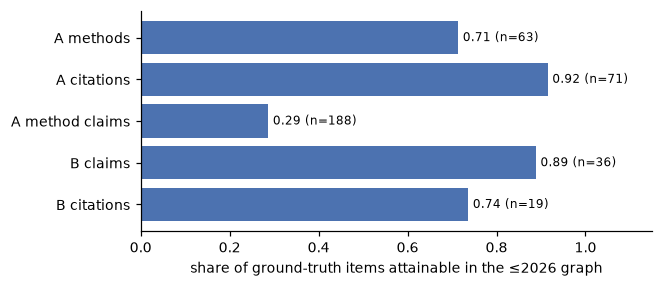

ceilings: {'A methods': 0.714, 'A citations': 0.915, 'A method claims': 0.287, 'B claims': 0.889, 'B citations': 0.737}
articles dated 2026 in the ≤2026 snapshot (not excludable for 'by Feb 2026' with yearly snapshots): 6


In [9]:
def frac(items, key):
    items = list(items)
    return sum(bool(key(x)) for x in items) / max(1, len(items)), len(items)


kinds = {"A methods": [r for g in GOLD.values() if g["type"] == "A" for r in g["methods"].values()],
         "A citations": [r for g in GOLD.values() if g["type"] == "A" for r in g["citations"].values()],
         "A method claims": [c for g in GOLD.values() if g["type"] == "A" for c in g["method_claims"]],
         "B claims": [c for g in GOLD.values() if g["type"] == "B" for c in g["claims"]],
         "B citations": [r for g in GOLD.values() if g["type"] == "B" for r in g["citations"].values()]}
keyf = {"A methods": lambda r: r["nodes"], "A citations": lambda r: r["articles"], "A method claims": lambda c: c["attainable"],
        "B claims": lambda c: c["attainable"], "B citations": lambda r: r["articles"]}
ceil = {k: frac(v, keyf[k]) for k, v in kinds.items()}
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(list(ceil), [f for f, _ in ceil.values()], color="#4c72b0")
for i, (f, n) in enumerate(ceil.values()):
    ax.text(f + 0.01, i, f"{f:.2f} (n={n})", va="center", fontsize=8)
ax.set_xlim(0, 1.15); ax.invert_yaxis(); ax.set_xlabel("share of ground-truth items attainable in the ≤2026 graph")
fig.savefig(FIG / "t6_attainability.png"); plt.show()
print("ceilings:", {k: round(f, 3) for k, (f, _) in ceil.items()})
print("articles dated 2026 in the ≤2026 snapshot (not excludable for 'by Feb 2026' with yearly snapshots):",
      sum(y == 2026 for y in SNAP[2026].year.values()))

**Outcome of §4:**
- The ceilings are well below 1 (printed above). Some GT methods are conceptual names ("physics-informed", "hybrid
  frameworks") or specific methods absent from the export (e.g. HamGNN); exact + acronym matching also leaves out
  versioned names ("Orb" for "Orb-v2"). Several type-B sources are not among the export's papers.
- Method claims are the scarcest target: a graph claim from the method's evidence article must be attached to the
  method.
- Hit-rates in §8 are over attainable items only, so they measure retrieval, not graph coverage.

## 5. The hierarchy as a search index

The coarsening algorithm writes, per snapshot, a laminar tree:
- L0 has 15 super-nodes, L1 60, L2 240 (P2 budgets);
- L0–L1 super-nodes carry an LLM label and gloss (P6), L2 has none;
- every leaf (graph node) sits in exactly one L2 super-node (P1).

A drill-down agent can only reach targets whose ancestors it keeps. The **target dispersion** below counts, per
question, how many super-nodes at each level hold at least one target. That count is the smallest beam that could keep
all targets if the ranking were perfect: an **oracle bound**.

This diagnostic reads the ground-truth targets directly, so it is for understanding only; it does not set the beam.

          2020  2022  2024  2026
L0          15    15    15    15
L1          60    60    60    60
L2         240   240   240   240
labelled    75    75    75    75
leaves    1475  2144  4094  5798
leaves of the answer kinds at ≤2026: {'A': 2524, 'B': 690}


,Q1,Q2,Q3,Q4,Q6,Q7,Q8,Q9,Q10,Q12,Q13,Q14,Q15,Q16,Q17,Q18
L0,5,3,2,1,1,1,1,2,1,4,4,6,1,2,3,3
L1,8,3,2,1,1,1,1,2,1,7,7,9,2,4,3,3
L2,10,3,2,2,1,1,1,2,1,10,10,11,2,4,4,3
targets,15,3,2,2,1,1,1,2,1,20,18,21,25,48,65,101


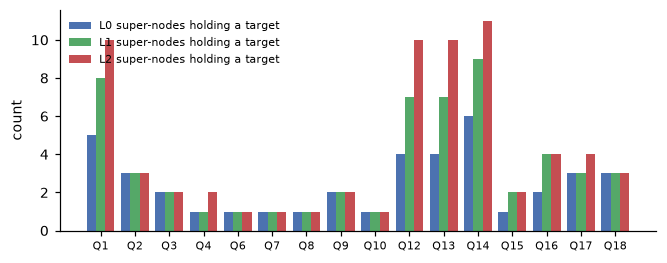

In [10]:
print(pd.DataFrame({c: {f"L{k}": sum(s["level"] == k for s in H[c]["supernodes"]) for k in range(H[c]["levels"])}
                    | {"labelled": sum(bool(s.get("label")) for s in H[c]["supernodes"]),
                       "leaves": len({v for s in H[c]["supernodes"] if s["level"] == 2 for v in s["member_ids"]})}
                    for c in CUTOFFS}))
S26 = SNAP[2026]
print("leaves of the answer kinds at ≤2026:", {t: sum(S26.type[v] in KINDS[t] for v in S26.ids) for t in KINDS})

sn26, _ = tree(RUN, 2026)   # tkh.retrieve
disp = {}
for q, g in GOLD.items():
    t = set(g["targets"])
    if t:
        disp[q] = {f"L{k}": sum(bool(t & set(s["member_ids"])) for s in sn26.values() if s["level"] == k) for k in range(3)}
        disp[q]["targets"] = len(t)
D = pd.DataFrame(disp).T
display(D.T)
fig, ax = plt.subplots(figsize=(7, 2.6))
x = np.arange(len(D))
for k, (lv, col) in enumerate(zip(("L0", "L1", "L2"), ("#4c72b0", "#55a868", "#c44e52"))):
    ax.bar(x + (k - 1) * 0.27, D[lv], width=0.27, label=f"{lv} super-nodes holding a target", color=col)
ax.set_xticks(x, D.index, fontsize=7); ax.set_ylabel("count"); ax.legend(fontsize=7, frameon=False)
fig.savefig(FIG / "t6_target_dispersion.png"); plt.show()

**Reading the dispersion results.** Two regimes appear:
- **Dispersed questions** have targets in several L0 super-nodes (the table above). For these, a small L0 beam cannot keep every target even with a perfect ranking, so the coarse grouping by use case
  matters. Intrinsic coherence per level is reported in `docs/report.md` §5.3.
- **Narrow questions** have all their targets inside a single L0 super-node. A beam reaches
  them only *if the right L0 and L1 nodes rank in the beam*. For these, reach depends on the routing score, not on
  dispersion.

Questions without attainable targets are left out. Recall should not be the only metric; inspection and
computation matter too (§7).

## 6. Agent: drill-down beam search and flat baseline

Implemented in `tkh/retrieve.py` (`leaf_texts`, `Index`, `descend`, `flat`, `extract`, `Agent`).

**Design choice D4, node content.** All of it is built from the snapshot's own edges (P6).
- **Leaf text:**
  - name and aliases;
  - the names of its relation neighbours over the clustering relations (`addresses`, `solves`, `extends`,
    `uses_component`, `uses_technique`, `evaluated_on`);
  - the `evaluated_on` metric and task;
  - the title of the article that presents it (method, **once**) or claims it (claim);
  - for a presented method, its paper's claims.
- **Super-node content:** label + gloss (L0–L1) and the centroid of its members' leaf vectors.
- `tkh.semantic.attached_text` is not used: it reads all edges of the export, which would leak later facts into
  earlier snapshots.

**Design choice D5, similarity: keyword overlap.** A text's score is the share of the question's keywords (those in the
snapshot's leaf vocabulary) that it contains. Keywords are word tokens (hyphens and `+` kept, so "DeepH-E3" stays one token), with English stop words and
the template words removed; the vocabulary is fitted per snapshot on leaf texts only. Texts and the question are
binary keyword vectors, and the question vector is divided by its keyword count.
- **Why overlap.** The questions are short and use the graph's own terms ("Hamiltonian", "equivariant"). Overlap
  counts each question keyword once, whereas TF-IDF down-weights terms shared by many leaves and BM25 also penalises
  long leaf texts.
- Clustering used a char-n-gram LSA of names, so this is a different ruler. It is not independent, though: names and
  clustering-relation neighbours are inside the leaf text. That partial overlap is stated, not hidden.
- An embedding model would be stronger on paraphrase, but it is a new dependency and download (not used).

**Design choice D6, drill-down.**
- L0–L1 super-node score = 0.5·s(q, label + gloss) + 0.5·s(q, centroid); L2 score = s(q, centroid). The centroid
  is the share of the super-node's members that contain each keyword.
- Beam widths (10, 20, 40) for 15 / 60 / 240 super-nodes: two thirds of L0, then a third and a sixth of the level's
  budget. L0 is kept wide because a top-level cluster is broad and its label is a coarse routing signal; the beam
  narrows as the clusters get more specific.
- The pool is the leaves of the kept L2 super-nodes that have the answer kinds, ranked by s(q, leaf).
- **Consequence, measured in §8:** L0 keeps 10 of 15 nodes (0.67); L1 and L2 then keep about half of their frontier.
  Pruning is spread over the three levels, and the drill-down scores the number of super-nodes per
  question printed in §8 (`diagnostics.supernodes_scored`).
- The question is stripped of template words and the date clause before encoding.

**Design choice D7, flat baseline.** The same scorer, leaf texts and answer kinds over every leaf. Only the search
differs, so any difference is the hierarchy's.

**Design choice D8, answer format.** The ground-truth format with k = 10 items, plus the node and article ids the
answer was read from (so scoring needs no string matching):
- **A:** `expected_methods`, `required_citations`, plus `method_claims` and `method_evidence` per returned method,
  read from up to 3 graph claims attached to it (by node id);
- **B:** `as_of`, `required_claims`, `sources` and `required_citations`.

In [11]:
print("beam:", BEAM, "| answer length k:", retrieve.K, "| claims per method:", retrieve.CLAIMS_PER_METHOD)
print("question encoding drops:", retrieve.TEMPLATE.pattern[:90], "…")

beam: (10, 20, 40) | answer length k: 10 | claims per method: 3
question encoding drops: \((?:by|as of)[^)]*\)|\b(?:which|what|are|is|the|methods?|best|suited|leading|most|importa …


In [12]:
agent = Agent(tkh, RUN, CUTOFFS)
qtext = qdf.set_index("question_id")["question"]
for qid in ("Q2", "Q15"):
    a = agent.answer(qtext[qid], gt[qid]["type"])
    print(f"{qid} -> snapshot {a['snapshot']}; super-nodes scored {a['n_supernodes_scored']}; pool {len(a['ranked'])}")
    for lv, (i, lab, sc) in a["closest"].items():
        print(f"   closest at {'L' + str(lv) if lv != 'leaf' else 'leaf'}: {i} {lab!r} ({sc})")
    show = a["expected_methods"] if gt[qid]["type"] == "A" else [c["text"][:90] for c in a["required_claims"]]
    print("   answer:", show[:5], "\n   citations:", a["required_citations"][:5])

Q2 -> snapshot 2026; super-nodes scored 137; pool 281
   closest at L0: L0.11 'Graph Neural Networks' (0.0451)
   closest at L1: L1.29 'Phonon Property Calculations' (0.0555)
   closest at L2: L2.151 None (0.1346)
   closest at leaf: meth_00222 'D4FT' (0.7692)
   answer: ['D4FT', 'Comprehensive review of AI-driven multiscale modeling approaches for solid-state physics and chemistry', 'EquiformerV2', 'DeepH-E3', 'Materials Project high-throughput computational workflow and open data platform'] 
   citations: ['Lin et al. 2023', 'Maevskiy et al. 2026', 'Rhodes et al. 2025', 'Zitnick et al. 2026', 'Zitnick et al. 2026']
Q15 -> snapshot 2026; super-nodes scored 137; pool 212
   closest at L0: L0.14 'Equivariant Graph Attention' (0.1446)
   closest at L1: L1.64 'Moiré Material Modeling' (0.166)
   closest at L2: L2.179 None (0.2857)
   closest at leaf: clai_00357 'Current challenges limiting AI-driven multiscale modeling include limited data availability, restricted model transferability, a

In [13]:
# P6 check on an earlier snapshot (all 18 questions use ≤2026, so this exercises the temporal path explicitly):
# a method published after 2020 that extends a ≤2020 node must not appear in that node's ≤2020 text or vocabulary.
S20, S26 = SNAP[2020], SNAP[2026]
t20, t26 = leaf_texts(tkh, S20), leaf_texts(tkh, S26)
e26 = S26.snap.edges
late = e26[(e26["article_year"] > 2020) & (e26["relation_type"] == "extends")]
pairs = [(t, m[0]) for m in late["members"] for t in m[1:] if t in S20.snap.node_ids and S20.name[m[0]] not in t20[t]]
assert pairs and all(S26.name[h] in t26[t] for t, h in pairs)
ix20 = Index(tkh, RUN, 2020)
late_only = {w for t, h in pairs for w in re.findall(r"[a-z][a-z0-9\-]{3,}", S26.name[h].lower())} - \
            {w for x in t20.values() for w in re.findall(r"[a-z][a-z0-9\-]{3,}", x.lower())}
late_vocab = set(agent.index(2026).vec.vocabulary_) - set(ix20.vec.vocabulary_)
assert ix20.encode(" ".join(late_only)).sum() == 0, "later words reach the ≤2020 query encoding"
assert not late_vocab & set(ix20.vec.vocabulary_)
print(f"P6 check: {len(pairs)} later 'extends' facts absent from ≤2020 texts; {len(late_only)} later-only words "
      f"encode to an empty ≤2020 query; {len(late_vocab)} ≤2026-only keywords absent from the ≤2020 index.")

P6 check: 52 later 'extends' facts absent from ≤2020 texts; 26 later-only words encode to an empty ≤2020 query; 3337 ≤2026-only keywords absent from the ≤2020 index.


**Outcome of §6:** the agent answers every question from its snapshot alone, in the ground-truth format, and the trace
shows the closest super-node at each level. The ≤2020 check confirms that later facts stay out of
the earlier snapshot's leaf texts, and that the ≤2020 index is fitted only on those texts: later-only words cannot
reach its query encoding. Aliases carry no date in the export and are taken as given (§9).

## 7. Metric design

Implemented in `eval/retrieval.py` (`score`, `summarise`, `diagnostics`, `retrieval_check`).

The unit is the question. Type A (n = 14) is the main set; type B (n = 4) is descriptive. All metrics are computed on
attainable items only, and the ceilings (§4) are reported beside them. There are four metrics: hit-rate for
accuracy, error rate for precision, items inspected for the reader's effort, and candidates scored for computation.
Every hit-rate is also reported *end to end*, over all GT items of its kind, with unattainable items counted as misses.

### Accuracy

**M1, item hit-rate @k.** The share of a question's attainable GT items found in its k = 10 answer.
- **Methods (A):** a GT method is hit if the answer contains one of its resolved nodes or a node with the same
  `name_key`.
- **Method claims (A):** attainable if the graph links a claim from one of the method's evidence articles to a
  resolved node of the method (§4). It is hit if the method is hit *and* one of the (up to 3) graph claims returned
  for that method comes from one of those articles. The test is per method, so all GT claims of a method are hit or
  missed together; the rate weights methods by their number of GT claims.
- **Claims (B):** a required claim is hit if the answer returns a claim of one of its source articles.
- **Citations (A, B):** a GT citation is hit if one of its resolved articles is among the answer's cited articles.

Claims are matched by source article, not by content: the GT claims are paraphrases, and matching their content needs
a semantic judge (§9, future work). One returned claim can therefore credit several required claims of the same
sources, and the claim hit-rates measure source-associated retrieval, not retrieval of each required claim.

**M2, error rate (A, where `fp_categories` exists).** The share of the k answers that resolve to `wrong_domain` or
`outdated_as_main` names. `valid_but_unlisted` answers are neutral, so the GT is not treated as exhaustive. Without
M2, a retriever that returns many plausible-but-wrong methods would look as good as one that returns correct ones.

### Effort

The cost of an answer has two parts. The reader inspects items; the agent scores candidates. One count cannot hold
both, so they are kept apart.

**M3, items inspected (the reader's effort).**
- **Targets are GT items**, not nodes. For A, each attainable GT method counts once, found at the first of its nodes;
  for B, each attainable required claim counts once, found at the first claim of its source articles.
- **Drill-down:** the labelled super-nodes (L0 and L1) shown on the way down, plus the rank of the item in the pool.
  L2 super-nodes carry no label; they are routed by centroid and count as computation.
- **Flat:** the item's rank among all leaves of the answer kinds.
- An item not in the drill-down pool is **censored** at N + 1 (N = the number of flat candidates: 2524 for A, 690
  for B).
- Reported to the first item and to 50% of the items, as **medians** with the share of questions reaching an item
  (*reach*). Means are not reported, because the censor value would set their size. Flat search ranks every
  leaf of the answer kinds, so its reach is 1 by construction; reach measures the targets drill-down loses by pruning.

**M4, candidates scored (computation).** Drill-down: every super-node scored at every level, plus the pooled leaves
ranked. Flat: every leaf of the answer kinds. It does not depend on the gold and is never censored. It is an operation
count, not a wall-clock latency, and it is not part of the count of measures favouring a system.

**Why the labels are counted.** The pool is a subset of the flat candidates scored by the same function, so a
target's rank in the pool is never worse than its global rank. Counting only the pool rank would favour the hierarchy
by construction. Charging the labels the reader reads keeps the comparison fair. Flat search's computation, scoring
every leaf, is charged in M4, not in M3.

### Protocol

- **Leakage guard.** The agent receives only `(question, type)`, and ground truth lives in the evaluator. §8 checks
  this in two ways: structurally (`tkh/retrieve.py` imports nothing from `eval` and never names the ground-truth
  file) and behaviourally (the evaluation rerun on a truncated copy of the ground truth gives identical answers in
  both modes).
- **Settings.** k = 10 and the agent settings (D4–D6) are fixed for the run; held-out validation of the settings is
  future work (§9).
- **Comparison.** Drill-down and flat answer the same questions, so differences are paired per question: the mean
  paired difference for hit-rates, the median paired difference for inspection and computation.

| Rejected alternative | Why |
|---|---|
| Raw recall against all GT items | Mixes graph coverage with retrieval failure |
| Inspection counting only the pool rank | Hides the labels read on the way down and favours the hierarchy |
| One step count adding super-nodes scored to the rank | Mixes the agent's computation with the reader's inspection, and charges flat search none of the leaves it scores |
| Dropping misses from inspection | Hides routing failures |
| A flat baseline with a different scorer | Credits the hierarchy with the scorer's gains |
| Lexical threshold for claim content | Arbitrary threshold, weak on paraphrase; source matching is deterministic |

In [14]:
# The evaluation exactly as `make retrieval` runs it (in memory; nothing is written)
RES, ANSWERS = retrieval_check(tkh, RUN, CUTOFFS, QUESTIONS, GT_PATH)
PER_Q = RES["per_question"]
HIER = {q: p["hier"] for q, p in PER_Q.items() if "hier" in p}
FLAT = {q: p["flat"] for q, p in PER_Q.items() if "flat" in p}
print("metrics.json['retrieval'] sections:", list(RES), "| questions:", len(PER_Q))

metrics.json['retrieval'] sections: ['config', 'summary', 'diagnostics', 'per_question'] | questions: 18


## 8. Results on all 18 questions

The leakage guard is checked first; then the summary (`metrics.json["retrieval"]["summary"]`), the per-question
table and the distribution of items inspected follow.
The reported results are those of `docs/appendix.md` Table A7.

In [15]:
# leakage guard: the agent module never imports the evaluator or names the ground-truth file, and the evaluation
# rerun on a truncated ground truth (one method / one claim per question) gives identical answers in both modes
src = inspect.getsource(retrieve)
assert "ground_truth" not in src and "eval" not in re.findall(r"^\s*(?:from|import) (\w+)", src, re.M)
cut = json.loads(GT_PATH.read_text())
for v in cut.values():
    if v["type"] == "A":
        v["expected_methods"] = v["expected_methods"][:1]
        for f in ("method_claims", "method_evidence"):
            v[f] = {m: x for m, x in v[f].items() if m in v["expected_methods"]}
    else:
        v["required_claims"] = v["required_claims"][:1]
with tempfile.TemporaryDirectory() as d:
    (Path(d) / "gt.json").write_text(json.dumps(cut))
    _, other = retrieval_check(tkh, RUN, CUTOFFS, QUESTIONS, Path(d) / "gt.json")
assert all(other[q][m] == ANSWERS[q][m] for q in ANSWERS for m in ("hier", "flat"))
print("leakage guard: tkh/retrieve.py reads no ground truth; answers are identical under a truncated ground truth")


def summary_table(summ):
    rows = []
    for t, ms in METRICS.items():
        for m in ms:
            r = summ[t][m]
            rows.append({"type": t, "metric": m + (" (median)" if r["stat"] == "median" else ""), "n": r["n"],
                         "drill-down": f"{r['hier']:.3f}", "flat": f"{r['flat']:.3f}",
                         "paired drill-down − flat": f"{r['hier_minus_flat']:+.3f}"})
    return pd.DataFrame(rows).set_index(["type", "metric"])


summary_table(RES["summary"])

leakage guard: tkh/retrieve.py reads no ground truth; answers are identical under a truncated ground truth


n drill-down      flat paired drill-down − flat
type metric                                                                  
A    methods                 12      0.251     0.295                   -0.044
     method_claims            9      0.306     0.306                   +0.000
     citations               14      0.664     0.578                   +0.087
     error_rate              12      0.042     0.033                   +0.008
     reached                 12      0.667     1.000                   -0.333
     inspect_first (median)  12     64.500    10.500                  +61.000
     inspect_half (median)   12    278.500    28.500                 +156.000
     scored (median)         14    571.500  2524.000                -1952.500
B    claims                   4      0.615     0.543                   +0.071
     citations                4      0.438     0.375                   +0.062
     reached                  4      1.000     1.000                   +0.000
     inspect_first (median)   4     63.000     2.000                  +61.000
     inspect_half (median)    4     65.500     6.500                  +59.500
     scored (median)          4    359.000   690.000                 -331.000

In [16]:
pq = pd.DataFrame({q: {f"{s}:{k}": (round(v, 2) if isinstance(v, float) else v) for s in ("hier", "flat")
                       for k, v in p.get(s, {}).items()} | {"pool": p.get("pool"), "supernodes": p.get("n_supernodes_scored")}
                   for q, p in PER_Q.items()}).T
cols = [c for c in pq.columns if any(c.endswith(x) for x in (":methods", ":claims", ":citations", ":inspect_first", ":scored", ":reached", ":lost_at_level"))]
pq[cols + ["pool", "supernodes"]]

,hier:methods,hier:citations,hier:scored,hier:reached,hier:inspect_first,hier:lost_at_level,flat:methods,flat:citations,flat:scored,flat:reached,flat:inspect_first,hier:claims,flat:claims,pool,supernodes
Q1,0.29,0.57,465,True,63,None,0.14,0.43,2524,True,7,NaN,NaN,326,139
Q2,0.5,0.57,418,True,63,None,1.0,0.71,2524,True,1,NaN,NaN,281,137
Q3,0.5,1.0,652,True,63,None,1.0,1.0,2524,True,2,NaN,NaN,513,139
Q4,0.0,1.0,529,False,2525,1,0.0,0.0,2524,True,42,NaN,NaN,389,140
Q5,None,0.0,576,NaN,NaN,NaN,None,0.0,2524,NaN,NaN,NaN,NaN,448,128
Q6,1.0,1.0,560,True,60,None,1.0,1.0,2524,True,1,NaN,NaN,422,138
Q7,0.0,1.0,601,False,2525,1,0.0,1.0,2524,True,1266,NaN,NaN,457,144
Q8,0.0,0.5,489,True,95,None,0.0,1.0,2524,True,78,NaN,NaN,346,143
Q9,0.0,1.0,567,False,2525,1,0.0,1.0,2524,True,22,NaN,NaN,419,148
Q10,0.0,0.25,606,False,2525,1,0.0,0.25,2524,True,1252,NaN,NaN,455,151


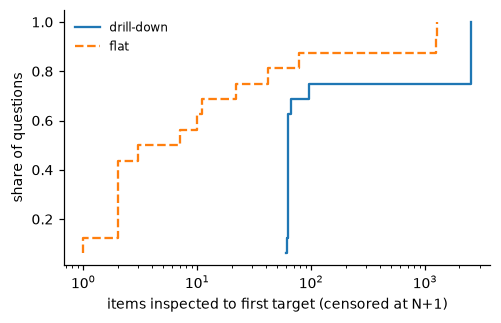

In [17]:
fig, ax = plt.subplots(figsize=(5, 3))
for res, lab, st in ((HIER, "drill-down", "-"), (FLAT, "flat", "--")):
    s = np.sort([r["inspect_first"] for r in res.values() if "inspect_first" in r])
    ax.step(s, np.arange(1, len(s) + 1) / len(s), st, where="post", label=lab)
ax.set_xscale("log"); ax.set_xlabel("items inspected to first target (censored at N+1)"); ax.set_ylabel("share of questions")
ax.legend(frameon=False, fontsize=8)
fig.savefig(FIG / "t6_inspect_ecdf.png"); plt.show()

In [18]:
# Key numbers (printed for checking against docs/appendix.md Table A7)
DG = RES["diagnostics"]
qa = [q for q in HIER if PER_Q[q]["type"] == "A" and "inspect_first" in HIER[q]]
qb = [q for q in HIER if PER_Q[q]["type"] == "B" and "inspect_first" in HIER[q]]
print(f"questions with targets: A {len(qa)}, B {len(qb)}")
for name, res in (("drill-down", HIER), ("flat", FLAT)):
    print(f"{name:10s} reached A {sum(res[q]['reached'] for q in qa)}/{len(qa)}, B {sum(res[q]['reached'] for q in qb)}/{len(qb)}; "
          f"median items inspected to first A {np.median([res[q]['inspect_first'] for q in qa]):.1f}, B {np.median([res[q]['inspect_first'] for q in qb]):.1f}")
print("kept / frontier per level:", {lv: {k: round(v, 2) for k, v in d.items()} for lv, d in DG["kept_over_frontier"].items()})
print("super-nodes scored per question:", DG["supernodes_scored"], "; labels shown:", DG["labels_shown"], "; pool:", DG["pool"])
print("drill-down never reaches {question: level at which the targets were lost}:", DG["never_reached"],
      "; targets in a single L0 super-node:", [q for q in DG["never_reached"] if D.loc[q, "L0"] == 1])
print("flat search needs > 1000 ranks on:", {q: FLAT[q]["inspect_first"] for q in qa + qb if FLAT[q]["inspect_first"] > 1000},
      "; drill-down on these:", {q: HIER[q]["inspect_first"] for q in qa + qb if FLAT[q]["inspect_first"] > 1000})
print("mean articles cited per answer (breadth diagnostic):", {t: {s: round(v, 1) for s, v in d.items()} for t, d in DG["articles_cited"].items()})
# Sanity checks: the tree's leaves cover every snapshot node of the answer kinds (the inspection censor N assumes it),
# and a full beam (every super-node kept) ranks exactly the flat candidate list
S, ix = SNAP[2026], agent.index(2026)
assert all(set(ix.leaves) >= {v for v in S.ids if S.type[v] in KINDS[t]} for t in KINDS)
full = Agent(tkh, RUN, CUTOFFS, beam=(15, 60, 240))
full._ix = agent._ix
assert all(full.answer(qtext[q], PER_Q[q]["type"], "hier")["ranked"] == agent.answer(qtext[q], PER_Q[q]["type"], "flat")["ranked"]
           for q in PER_Q)
print("tree leaves cover all answer-kind nodes; full beam ranks the same list as flat on all 18 questions")

questions with targets: A 12, B 4
drill-down reached A 8/12, B 4/4; median items inspected to first A 64.5, B 63.0
flat       reached A 12/12, B 4/4; median items inspected to first A 10.5, B 2.0
kept / frontier per level: {'L0': {'mean': 0.67, 'min': 0.67, 'max': 0.67}, 'L1': {'mean': 0.45, 'min': 0.41, 'max': 0.51}, 'L2': {'mean': 0.5, 'min': 0.46, 'max': 0.54}}
super-nodes scored per question: {'min': 128, 'max': 151} ; labels shown: {'min': 54, 'max': 64} ; pool: {'min': 208, 'max': 513}
drill-down never reaches {question: level at which the targets were lost}: {'Q4': 1, 'Q7': 1, 'Q9': 1, 'Q10': 1} ; targets in a single L0 super-node: ['Q4', 'Q7', 'Q10']
flat search needs > 1000 ranks on: {'Q7': 1266, 'Q10': 1252} ; drill-down on these: {'Q7': 2525, 'Q10': 2525}
mean articles cited per answer (breadth diagnostic): {'A': {'hier': 12.9, 'flat': 13.2}, 'B': {'hier': 3.5, 'flat': 4.0}}
tree leaves cover all answer-kind nodes; full beam ranks the same list as flat on all 18 questions


## 9. Findings, implementation and future work

### What the evaluation shows

The results of the shipped run are in the report:
- **`docs/appendix.md` Table A7:** every measure, with attainable and total counts and end-to-end rates;
- **`docs/report.md` Table 3:** the headline rows.

This section says what they mean and quotes no numbers. They are point estimates on few questions (14 type A,
4 type B), without CIs, and the settings (D4–D6) were chosen with these questions in view, so they may be optimistic.

- **Reach.** The drill-down misses some type-A questions that flat search reaches. The misses are routing errors at
  L1: the L0 super-node holding the targets is kept, then the L1 super-node holding them is dropped (Table A7 note).
- **Accuracy (M1) is mixed.** The drill-down is ahead of flat search on some hit-rates and behind on others. Claim
  hit-rates are credited by source article, so they do not show that the required claims themselves were found.
- **Precision (M2).** Both systems rarely return a listed wrong-domain or outdated method.
- **Inspection (M3) and computation (M4) point in opposite directions.** The drill-down ranks only its pool, so it
  scores far fewer candidates than flat search. The reader, however, reads the L0 and L1 labels on the way down, so
  more items are inspected before the first target.
- **Sanity checks.** §8 asserts that the tree's leaves cover every node of the answer kinds, that a full beam
  (15, 60, 240) ranks the same list as flat search, and the leakage guard; §6 asserts the ≤2020 temporal check.

On these questions, the hierarchy acts as a cheaper filter over the candidates, not as a shortcut to the first target.
Its utility for navigation is mixed and not established (`docs/report.md` §5.4).

### Implementation

1. **Modules:**
   - `tkh/retrieve.py`: the agent only (§6); it sees `(question, type)`;
   - `eval/retrieval.py`: gold resolution (§4), the metrics M1–M4 (§7), the summary and diagnostics;
   - CLI `python -m eval retrieval --run out` (`make retrieval`, part of `make all`; offline, seconds), writing
     `metrics.json["retrieval"]` and `out/retrieval_answers.json`; the results are in `docs/report.md` §5.
2. **Gold resolution (evaluator):**
   - methods by exact name/alias or acronym, over the answer kinds of type A;
   - citations by author set + year ±1 + hint; each `;`-separated part of an evidence source resolved on its own;
   - type-B sources by DOI, then title;
   - method claims attainable only with a graph claim from the evidence article on the method;
   - report ceilings with every hit-rate.
3. **Agent:** the snapshot rule (D1), snapshot-only node text with the presenting paper's claims (D4), keyword
   overlap fitted per snapshot (D5), the label + centroid blend, beam (10, 20, 40) and the template-stripped question (D6), k = 10, the flat baseline with the same scorer (D7), answers in the GT format with
   node and article ids (D8).
4. **`metrics.json["retrieval"]`:** `summary` (per question type and metric: n, the mean or median per system and of
   the paired differences, end-to-end hit-rates, and the ceilings), `diagnostics` (kept/frontier, super-nodes scored,
   labels shown, pool size, misses with the level
   at which they were lost, articles cited), `per_question` and `config`. The answers, traces and resolved gold go to
   `out/retrieval_answers.json`.
5. **Checks** (run in this notebook):
   - a later edge never reaches an earlier snapshot's text or vocabulary (§6);
   - the leakage guard (§8);
   - the tree's leaves cover every node of the answer kinds, and a full beam (15, 60, 240) ranks the same list as
     flat search (§8).

### Assumptions, simplifications and directions for future work

**Assumptions**, each a check for future work:
- A node matched by exact name or acronym is the method the GT means.
- A graph claim from a claim's source article supports the GT claim (source match, not content match).
- An ambiguous citation counts as hit if any of its candidate articles is cited.
- "By Feb 2026" is answered from the ≤2026 snapshot, which also holds papers published later in 2026.
- Aliases, which carry no date in the export, do not leak later information into earlier snapshots.
- Lexical similarity is an adequate proxy for meaning; it partly overlaps the names used for clustering (D5).
- L2 super-nodes carry no label, so L2 routing relies on the member centroid alone.
- Author order is absent from the export, so citations match by author set.
- The agent settings (D4–D6), chosen with these questions in view, generalise to new questions.
- The 18 questions represent the intended use; all of them are answered from the ≤2026 snapshot, so retrieval on
  earlier snapshots is untested beyond the §6 check.

**Simplifications**, each a direction for future work:
- **Matching:** a looser method rule (prefix, version-aware) for names such as "Orb" → "Orb-v2", reported as a
  separate tier.
- **Per-claim matching:** each GT method claim matched to its own evidence source, not to the union of the method's
  sources.
- **Claim content:** a semantic judge (e.g. an LLM entailment check) to match GT claim text and evidence against the
  returned claims, with `distractor_note` as negative checks and a shuffled-answer control.
- **Multi-source claims:** a strict tier requiring every source of a claim, informed by `independence`.
- **Stratification:** hit-rates by `coverage` and `evidence_type`; contrast sources (`contrast_sources`) scored
  separately.
- **Citation breadth control:** articles cited and citation precision, since citation hit-rate rises with breadth
  alone.
- **Temporal compliance:** the share of cited articles dated within the GT `as_of` (the snapshot check against the
  evaluator's date is implemented: `per_question.<q>.snapshot_ok`).
- **Budget-matched recall:** recall at an equal number of inspected items, with its area under the curve.
- **Null models (a validity criterion of the brief, stated for coherence):** a size-preserving random tree, to test whether the grouping helps beyond
  chance; a label-free ablation, to isolate the contribution of the labels.
- **Statistics (a validity criterion of the brief, stated for stability):** paired bootstrap CIs over questions for every difference.
- **Held-out validation of the settings:** a development/test split of the questions, comparing scorer, beam and
  node content on the first and reporting held-out hit-rates and inspection on the second.
- **More questions:** more question–answer pairs, including synthetic ones, to enlarge the set.
- **Routing:** a beam that adapts to the frontier or to the score distribution; embeddings for paraphrase; better
  L1 routing for questions whose targets are pruned (§8).
- **Questions on earlier snapshots,** to test the temporal dimension of retrieval.
- **Worked traces** in the report: one success and one L1 routing failure (Q4 or Q10), read from the drill-down trace.